# Fase 0c — Valores únicos y frecuencias de los datos crudos de estaciones

Inventario de **cada variable** de los tres archivos originales, antes de cualquier depuración: cuántos valores distintos tiene, cuántas veces sale cada uno y cómo cambia por año.

Variables: `STATION_ID`, `YEAR`, `MONTH`, `DAY`, `VALUE` (más `archivo`, el archivo de origen).

> **¿Se hicieron imputaciones?** No. Hasta ahora **no se ha imputado ningún valor**. En el notebook 01 los días problemáticos (valor imposible, total mensual en un día, años copiados, rachas de ceros falsos) se **convirtieron en faltantes**, y se eligieron los pares estación‑año con suficiente cobertura. En el notebook 03 las curvas se construyen por mínimos cuadrados **solo con los días observados**: la base B‑spline pasa por encima de los huecos cortos sin inventar datos diarios. Sí se rellenan tres cosas, y no son imputaciones de estaciones: el satélite entregado trae el océano relleno (lo hizo su productor), los archivos de claves de CHIRPS se regeneraron y el 29 de febrero se eliminó.

In [ ]:
# Verificación reproducible: no reinstala paquetes presentes ni instala sin autorización.
from importlib.util import find_spec
import subprocess
import sys

INSTALAR_FALTANTES = False  # Cambiar a True únicamente si se autoriza instalar en este entorno.
PAQUETES_REQUERIDOS = {'pandas': 'pandas', 'numpy': 'numpy', 'matplotlib': 'matplotlib'}
faltantes = {modulo: paquete for modulo, paquete in PAQUETES_REQUERIDOS.items()
             if find_spec(modulo) is None}

if faltantes and INSTALAR_FALTANTES:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *faltantes.values()])
    faltantes = {modulo: paquete for modulo, paquete in PAQUETES_REQUERIDOS.items()
                 if find_spec(modulo) is None}

if faltantes:
    comando = f"{sys.executable} -m pip install {' '.join(faltantes.values())}"
    raise ModuleNotFoundError(
        f"Faltan dependencias: {faltantes}. No se instalaron automáticamente. "
        f"Autorice la instalación o ejecute: {comando}"
    )

versiones = {modulo: __import__(modulo).__version__
             for modulo in PAQUETES_REQUERIDOS
             if hasattr(__import__(modulo), '__version__')}
print('Dependencias verificadas:', versiones)


In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 9})
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)
ROOT = Path.cwd(); E0 = ROOT / "eda_fase0"; OUT = E0 / "valores_unicos"; OUT.mkdir(exist_ok=True)
raw = pd.read_pickle(E0 / "estaciones_crudas.pkl")        # caché creada por el notebook 01 (datos tal cual)
print(raw.shape)


(2992694, 6)


## 1. Resumen por variable

In [2]:
filas = []
for c in ["STATION_ID", "YEAR", "MONTH", "DAY", "VALUE", "archivo"]:
    s = raw[c]; vc = s.value_counts()
    filas.append({"variable": c, "tipo": str(s.dtype), "nulos": int(s.isna().sum()), "valores_unicos": s.nunique(),
                  "mínimo": s.min(), "máximo": s.max(), "más frecuente": vc.index[0], "veces que sale": int(vc.iloc[0]),
                  "valores que salen 1 sola vez": int((vc == 1).sum())})
display(pd.DataFrame(filas).set_index("variable"))
display(raw.groupby("archivo").agg(**{f"únicos_{c}": (c, "nunique") for c in ["STATION_ID", "YEAR", "MONTH", "DAY", "VALUE"]}))


,tipo,nulos,valores_unicos,mínimo,máximo,más frecuente,veces que sale,valores que salen 1 sola vez
variable,,,,,,,,
STATION_ID,int64,0,344,2610000101,5421240201,2612700201,25728,0
YEAR,int64,0,74,1930,2003,1990,96211,0
MONTH,int64,0,12,1,12,8,255198,0
DAY,int64,0,31,1,31,23,98446,0
VALUE,float64,0,1341,0.0,859375.0,0.0,1734840,368
archivo,str,0,3,P_1930_1979.xlsx,P_1991_2003.csv,P_1991_2003.csv,1010677,0


,únicos_STATION_ID,únicos_YEAR,únicos_MONTH,únicos_DAY,únicos_VALUE
archivo,,,,,
P_1930_1979.xlsx,264,50,12,31,750
P_1980_1990.csv,302,11,12,31,967
P_1991_2003.csv,284,13,12,31,1151


**Lectura.** Las variables de calendario tienen exactamente los valores esperados (12 meses, 31 días). Hay 344 estaciones y 74 años (1930–2003). `VALUE` tiene 1 341 valores distintos, una cantidad baja para 3 millones de registros porque casi todo está en milímetros enteros (ver §5).

## 2. `STATION_ID`: cuántas veces sale cada estación y en qué años

Registros por estación: mínimo 12, mediana 9,116, máximo 25,728


,registros,primer_anio,ultimo_anio,anios_con_datos,archivos,ceros_pct,media_mm,registros_por_anio
STATION_ID,,,,,,,,
2612700201,25728,1932,2003,72,"P_1930_1979.xlsx, P_1980_1990.csv, P_1991_2003...",66.6,3.102266,357.0
2612700202,24111,1930,2003,68,"P_1930_1979.xlsx, P_1980_1990.csv, P_1991_2003...",68.7,2.741587,355.0
2620500201,21786,1941,2003,63,"P_1930_1979.xlsx, P_1980_1990.csv, P_1991_2003...",53.7,5.641190,346.0
2622400101,21166,1935,2003,62,"P_1930_1979.xlsx, P_1980_1990.csv, P_1991_2003...",66.9,3.033833,341.0
2611400101,20591,1946,2003,58,"P_1930_1979.xlsx, P_1980_1990.csv, P_1991_2003...",51.4,5.442251,355.0
2620000101,20458,1946,2003,58,"P_1930_1979.xlsx, P_1980_1990.csv, P_1991_2003...",55.0,4.848636,353.0
2622100301,20358,1946,2003,58,"P_1930_1979.xlsx, P_1980_1990.csv, P_1991_2003...",53.0,7.970233,351.0
2611200101,20224,1946,2003,58,"P_1930_1979.xlsx, P_1980_1990.csv, P_1991_2003...",66.8,3.607644,349.0
2620000102,18388,1952,2003,52,"P_1930_1979.xlsx, P_1980_1990.csv, P_1991_2003...",58.2,7.029269,354.0


,registros,primer_anio,ultimo_anio,anios_con_datos,archivos,ceros_pct,media_mm,registros_por_anio
STATION_ID,,,,,,,,
2612200201,426,1988,1989,2,P_1980_1990.csv,59.6,3.833333,213.0
2610000109,365,1990,1990,1,P_1980_1990.csv,70.1,2.712329,365.0
5301000101,334,1994,1995,2,P_1991_2003.csv,12.0,35.619760,167.0
5420800101,330,1993,1994,2,P_1991_2003.csv,31.2,14.163636,165.0
5421200112,299,1981,1987,7,P_1980_1990.csv,0.7,141.090301,43.0
5420410104,190,1990,1990,1,P_1980_1990.csv,64.7,2.131579,190.0
2610000201,31,1998,1998,1,P_1991_2003.csv,74.2,3.645161,31.0
2613100105,31,1994,1994,1,P_1991_2003.csv,38.7,6.612903,31.0
2620000201,30,1993,1993,1,P_1991_2003.csv,26.7,13.200000,30.0


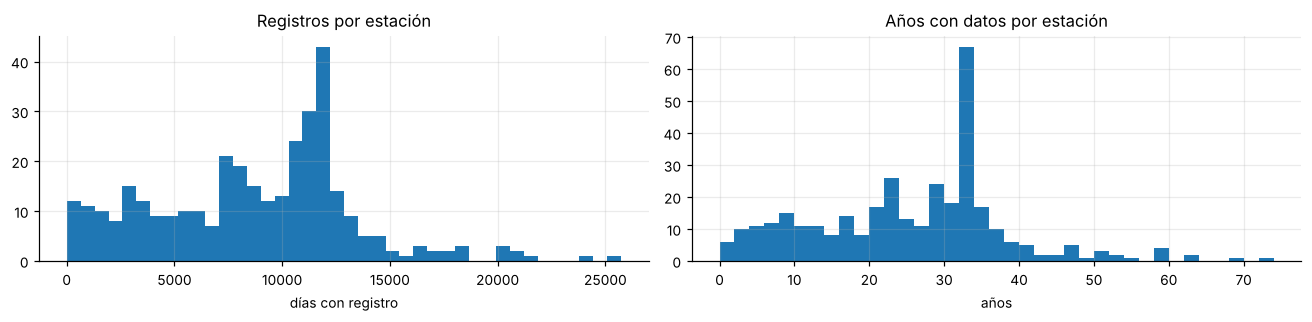

In [3]:
por_est = (raw.groupby("STATION_ID")
              .agg(registros=("VALUE", "size"), primer_anio=("YEAR", "min"), ultimo_anio=("YEAR", "max"),
                   anios_con_datos=("YEAR", "nunique"), archivos=("archivo", lambda s: ", ".join(sorted(s.unique()))),
                   ceros_pct=("VALUE", lambda v: round(100 * (v == 0).mean(), 1)), media_mm=("VALUE", "mean"))
              .sort_values("registros", ascending=False))
por_est["registros_por_anio"] = (por_est.registros / por_est.anios_con_datos).round(0)
print(f"Registros por estación: mínimo {por_est.registros.min():,}, mediana {por_est.registros.median():,.0f}, máximo {por_est.registros.max():,}")
display(por_est.head(10)); display(por_est.tail(10))
por_est.to_csv(OUT / "conteo_por_estacion.csv")

fig, ax = plt.subplots(1, 2, figsize=(12, 3))
ax[0].hist(por_est.registros, bins=40); ax[0].set(title="Registros por estación", xlabel="días con registro")
ax[1].hist(por_est.anios_con_datos, bins=range(0, 76, 2)); ax[1].set(title="Años con datos por estación", xlabel="años")
plt.tight_layout(); plt.show()


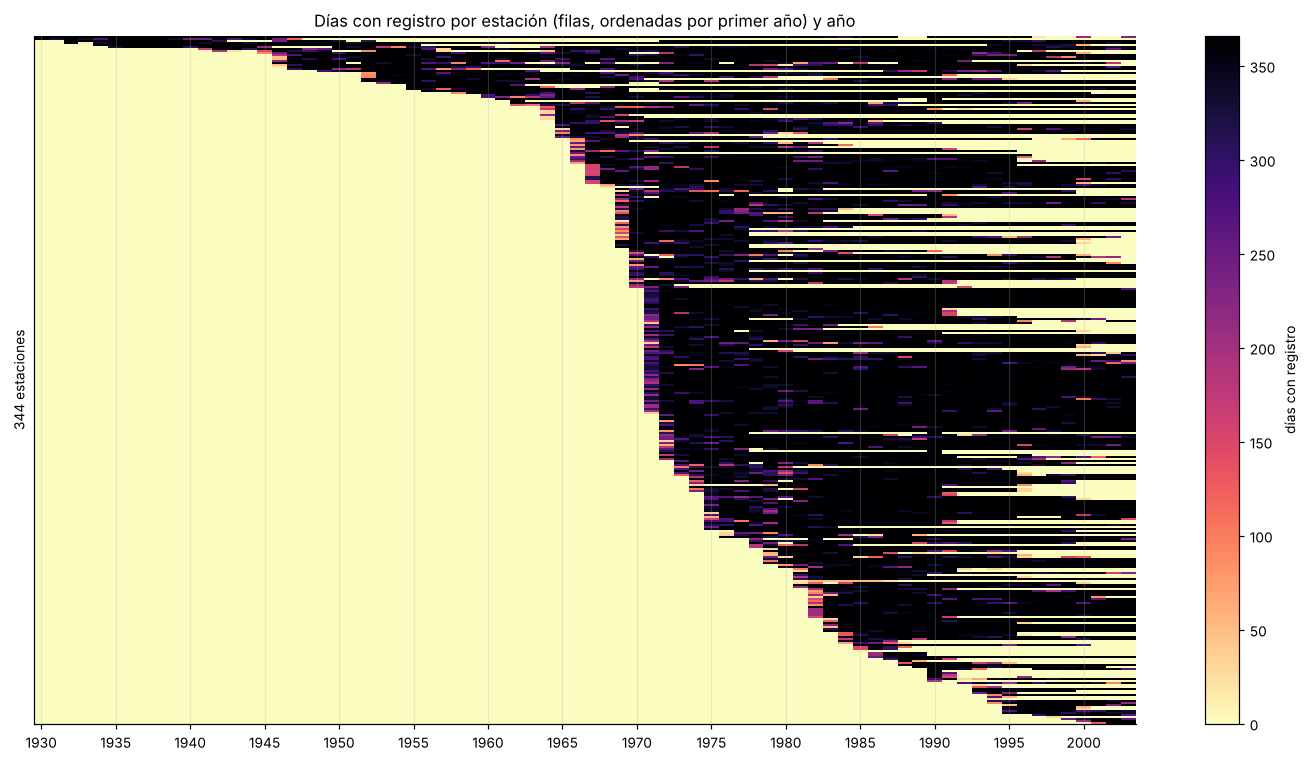

Pares estación‑año con registros: 8657 | con 365/366 días: 6062 | con exactamente 12 días (un registro por mes): 4


In [4]:
# Registros por estación y año (cuántos días aparece cada estación en cada año)
est_anio = raw.pivot_table(index="STATION_ID", columns="YEAR", values="VALUE", aggfunc="size", fill_value=0)
est_anio.to_csv(OUT / "conteo_estacion_por_anio.csv")
fig, ax = plt.subplots(figsize=(13, 7))
im = ax.imshow(est_anio.loc[por_est.sort_values("primer_anio").index].values, aspect="auto", cmap="magma_r",
               vmin=0, vmax=366, interpolation="nearest")
ax.set_xticks(range(0, est_anio.shape[1], 5)); ax.set_xticklabels(est_anio.columns[::5])
ax.set_yticks([]); ax.set(title="Días con registro por estación (filas, ordenadas por primer año) y año", ylabel="344 estaciones")
plt.colorbar(im, ax=ax, label="días con registro"); plt.tight_layout(); plt.show()
dist = pd.Series(est_anio.values.ravel()); dist = dist[dist > 0]
print("Pares estación‑año con registros:", len(dist), "| con 365/366 días:", int((dist >= 365).sum()),
      "| con exactamente 12 días (un registro por mes):", int((dist == 12).sum()))


## 3. `YEAR`: cuántos registros y estaciones hay cada año

YEAR,1930,1931,1932,1933,1934,1935,1936,1937,1938,1939,1940,1941,1942,1943,1944,...,1989,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003
registros,730,698,1464,1075,1705,2159,2196,2190,2190,2159,2012,2202,2678,2121,2073,...,93091,96211,88387,84534,84150,85394,86011,79743,78227,77371,77412,69188,67722,66430,66108
estaciones,2,2,4,4,5,6,6,6,6,6,6,7,8,7,6,...,263,270,258,238,239,246,245,233,219,217,220,209,192,190,187
archivo,P_1930_1979.xlsx,P_1930_1979.xlsx,P_1930_1979.xlsx,P_1930_1979.xlsx,P_1930_1979.xlsx,P_1930_1979.xlsx,P_1930_1979.xlsx,P_1930_1979.xlsx,P_1930_1979.xlsx,P_1930_1979.xlsx,P_1930_1979.xlsx,P_1930_1979.xlsx,P_1930_1979.xlsx,P_1930_1979.xlsx,P_1930_1979.xlsx,...,P_1980_1990.csv,P_1980_1990.csv,P_1991_2003.csv,P_1991_2003.csv,P_1991_2003.csv,P_1991_2003.csv,P_1991_2003.csv,P_1991_2003.csv,P_1991_2003.csv,P_1991_2003.csv,P_1991_2003.csv,P_1991_2003.csv,P_1991_2003.csv,P_1991_2003.csv,P_1991_2003.csv
dias_del_anio,365,365,366,365,365,365,366,365,365,365,366,365,365,365,366,...,365,365,365,366,365,365,365,366,365,365,365,366,365,365,365
registros_esperados,730,730,1464,1460,1825,2190,2196,2190,2190,2190,2196,2555,2920,2555,2196,...,95995,98550,94170,87108,87235,89790,89425,85278,79935,79205,80300,76494,70080,69350,68255
completitud_%,100.0,95.6,100.0,73.6,93.4,98.6,100.0,100.0,100.0,98.6,91.6,86.2,91.7,83.0,94.4,...,97.0,97.6,93.9,97.0,96.5,95.1,96.2,93.5,97.9,97.7,96.4,90.4,96.6,95.8,96.9


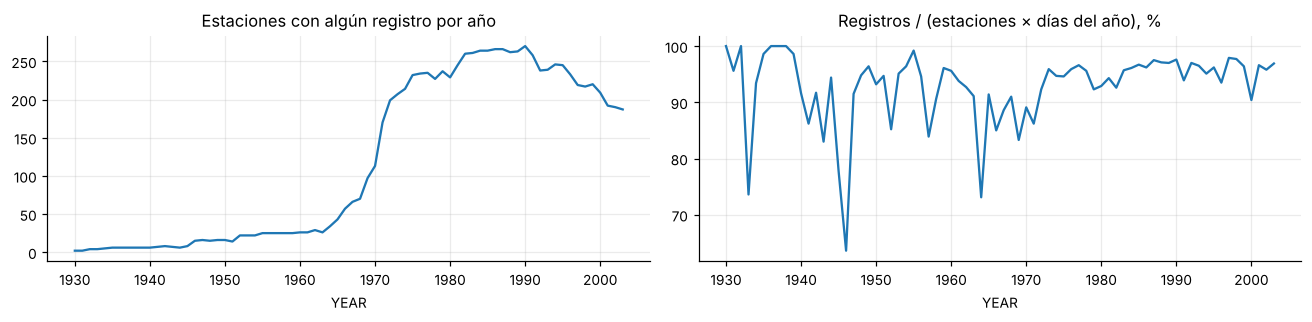

In [5]:
por_anio = raw.groupby("YEAR").agg(registros=("VALUE", "size"), estaciones=("STATION_ID", "nunique"),
                                   archivo=("archivo", lambda s: ", ".join(sorted(s.unique()))))
por_anio["dias_del_anio"] = [366 if (y % 4 == 0 and (y % 100 != 0 or y % 400 == 0)) else 365 for y in por_anio.index]
por_anio["registros_esperados"] = por_anio.estaciones * por_anio.dias_del_anio
por_anio["completitud_%"] = (100 * por_anio.registros / por_anio.registros_esperados).round(1)
display(por_anio.T)
por_anio.to_csv(OUT / "conteo_por_anio.csv")
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
por_anio.estaciones.plot(ax=ax[0], title="Estaciones con algún registro por año")
por_anio["completitud_%"].plot(ax=ax[1], title="Registros / (estaciones × días del año), %")
plt.tight_layout(); plt.show()


## 4. `MONTH` y `DAY`: ¿algún mes o día aparece de más o de menos?

Si los registros fueran parejos, cada mes tendría una proporción proporcional a sus días y los días 1–28 saldrían igual de seguido. Los días 29, 30 y 31 salen menos porque no todos los meses los tienen. Un exceso en el **día 31 o en el último día del mes** delata los totales mensuales digitados en un solo día.

,1,2,3,4,5,6,7,8,9,10,11,12
registros,251286.00,229885.00,253564.00,245246.00,253508.00,246508.00,254614.00,255198.00,247291.00,254989.00,246378.00,254227.00
% observado,8.40,7.68,8.47,8.19,8.47,8.24,8.51,8.53,8.26,8.52,8.23,8.49
% esperado por días,8.49,7.73,8.49,8.21,8.49,8.21,8.49,8.49,8.21,8.49,8.21,8.49


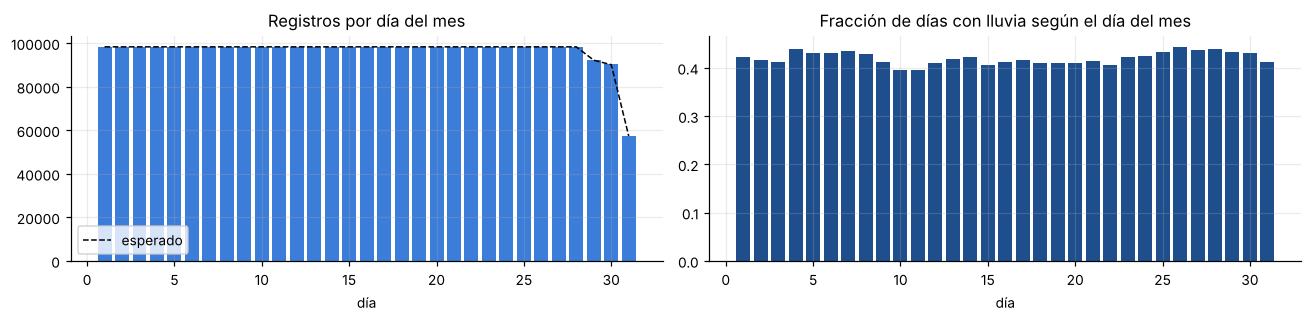

In [6]:
mes = raw.MONTH.value_counts().sort_index()
esperado_mes = pd.Series([31, 28.25, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31], index=range(1, 13))
tabla_mes = pd.DataFrame({"registros": mes, "% observado": (100 * mes / mes.sum()).round(2),
                          "% esperado por días": (100 * esperado_mes / esperado_mes.sum()).round(2)})
display(tabla_mes.T)

dia = raw.DAY.value_counts().sort_index()
meses_con_dia = pd.Series({d: (12 if d <= 28 else 11.25 if d == 29 else 11 if d == 30 else 7) for d in range(1, 32)})
esperado_dia = dia.loc[1:28].mean() * meses_con_dia / 12
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
ax[0].bar(dia.index, dia.values, color="#3b7dd8"); ax[0].plot(esperado_dia.index, esperado_dia.values, "k--", lw=1, label="esperado")
ax[0].set(title="Registros por día del mes", xlabel="día"); ax[0].legend()
# solo valores > 0: ¿en qué día del mes cae la lluvia?
dia_lluvia = raw[raw.VALUE > 0].DAY.value_counts().sort_index()
ax[1].bar(dia_lluvia.index, dia_lluvia.values / dia.values, color="#1f4e8c")
ax[1].set(title="Fracción de días con lluvia según el día del mes", xlabel="día"); plt.tight_layout(); plt.show()

mes_anio = raw.pivot_table(index="YEAR", columns="MONTH", values="VALUE", aggfunc="size", fill_value=0)
mes_anio.to_csv(OUT / "conteo_mes_por_anio.csv")


## 5. `VALUE`: valores únicos y cuántas veces sale cada uno

In [7]:
vc = raw.VALUE.value_counts()
frec = pd.DataFrame({"veces": vc, "%": (100 * vc / vc.sum()).round(3)})
frec["% acumulado"] = frec["%"].cumsum().round(2)
print(f"Valores distintos: {len(vc)} | enteros: {(vc.index % 1 == 0).sum()} | con decimales: {(vc.index % 1 != 0).sum()}")
print(f"Valores que salen una sola vez: {(vc == 1).sum()} (casi todos grandes: mediana {vc[vc == 1].index.to_series().median():.0f} mm)")
display(frec.head(25).T)
frec.to_csv(OUT / "frecuencia_de_cada_valor.csv")


Valores distintos: 1341 | enteros: 344 | con decimales: 997
Valores que salen una sola vez: 368 (casi todos grandes: mediana 117 mm)


VALUE,0.0,1.0,2.0,3.0,5.0,4.0,10.0,6.0,7.0,8.0,9.0,15.0,20.0,12.0,11.0,13.0,14.0,18.0,30.0,16.0,25.0,17.0,19.0,22.0,21.0
veces,1734840.000,127542.000,118104.000,91084.000,85464.000,75746.000,73563.000,53357.000,45835.000,45476.00,35388.000,35334.000,33371.000,32579.000,27906.000,22790.000,21909.000,18353.000,17918.000,17224.000,16018.000,15622.000,13296.000,12788.000,11152.000
%,57.969,4.262,3.946,3.044,2.856,2.531,2.458,1.783,1.532,1.52,1.182,1.181,1.115,1.089,0.932,0.762,0.732,0.613,0.599,0.576,0.535,0.522,0.444,0.427,0.373
% acumulado,57.970,62.230,66.180,69.220,72.080,74.610,77.070,78.850,80.380,81.90,83.080,84.260,85.380,86.470,87.400,88.160,88.890,89.510,90.110,90.680,91.220,91.740,92.180,92.610,92.980


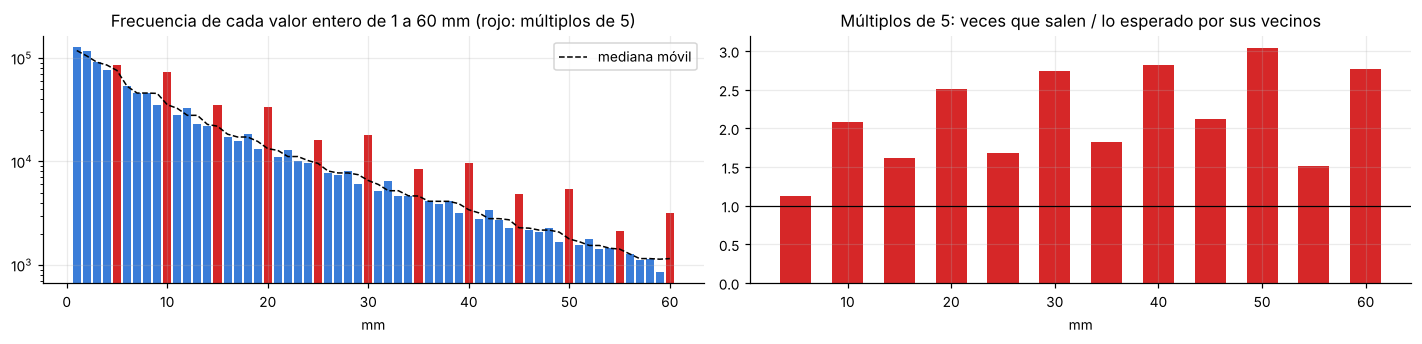

Exceso medio en múltiplos de 5 (5 a 60 mm): 2.15 veces lo esperado


In [8]:
# Preferencia de dígito: ¿se redondeaba a múltiplos de 5?
ent = raw.VALUE[(raw.VALUE >= 1) & (raw.VALUE <= 60) & (raw.VALUE % 1 == 0)].astype(int)
cnt = ent.value_counts().sort_index()
suave = cnt.rolling(5, center=True, min_periods=1).median()
fig, ax = plt.subplots(1, 2, figsize=(13, 3.2))
col = ["#d62728" if v % 5 == 0 else "#3b7dd8" for v in cnt.index]
ax[0].bar(cnt.index, cnt.values, color=col); ax[0].plot(suave.index, suave.values, "k--", lw=1, label="mediana móvil")
ax[0].set_yscale("log"); ax[0].set(title="Frecuencia de cada valor entero de 1 a 60 mm (rojo: múltiplos de 5)", xlabel="mm"); ax[0].legend()
exceso = (cnt / suave)[cnt.index % 5 == 0]
ax[1].bar(exceso.index, exceso.values, width=3, color="#d62728"); ax[1].axhline(1, c="k", lw=.8)
ax[1].set(title="Múltiplos de 5: veces que salen / lo esperado por sus vecinos", xlabel="mm"); plt.tight_layout(); plt.show()
print("Exceso medio en múltiplos de 5 (5 a 60 mm):", round(float(exceso.mean()), 2), "veces lo esperado")


YEAR,1930,1931,1932,1933,1934,1935,1936,1937,1938,1939,1940,1941,1942,1943,1944,...,1989,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003
valores_distintos,39.00,40.00,45.00,60.00,54.00,63.00,71.00,54.00,65.00,44.00,51.00,50.00,79.00,60.00,54.00,...,482.00,479.00,463.00,450.00,513.00,499.00,527.00,568.00,463.00,503.00,613.00,472.00,475.00,280.00,164.00
ceros_pct,75.75,71.63,69.67,68.74,65.81,69.71,75.82,71.28,66.03,74.57,77.04,77.48,62.06,61.20,62.76,...,57.14,60.88,61.26,64.43,56.68,57.15,57.73,53.81,63.71,59.01,48.47,53.43,63.93,66.38,63.50
decimales_pct,0.00,0.00,0.00,0.00,0.00,0.00,0.46,0.00,0.00,0.00,0.00,0.05,0.00,0.00,0.00,...,1.11,0.96,0.96,1.00,1.42,1.36,1.56,2.25,1.89,2.67,3.59,1.75,1.44,0.36,0.04
multiplos5_pct,19.21,11.11,18.24,16.67,18.01,23.09,25.14,19.08,18.01,19.49,20.78,15.96,17.42,18.59,15.16,...,23.79,23.38,22.05,22.47,23.74,23.55,23.64,24.53,23.75,24.03,24.42,22.73,23.49,23.05,24.24
maximo,91.00,64.00,105.00,307.00,132.00,90.00,103.00,88.00,102.00,75.00,85.00,145.00,160.00,106.00,83.00,...,388.00,240.60,421.00,232.10,310.70,560.00,380.00,503.00,288.00,260.00,207.00,259.00,277.00,335.00,600.00
mediana_lluvia,6.00,6.00,6.00,9.00,6.00,8.00,7.00,7.00,8.00,5.00,6.00,6.00,8.00,7.00,5.00,...,7.00,7.00,7.00,7.00,8.00,8.00,8.00,8.00,8.00,7.00,8.00,7.00,7.00,7.00,8.00


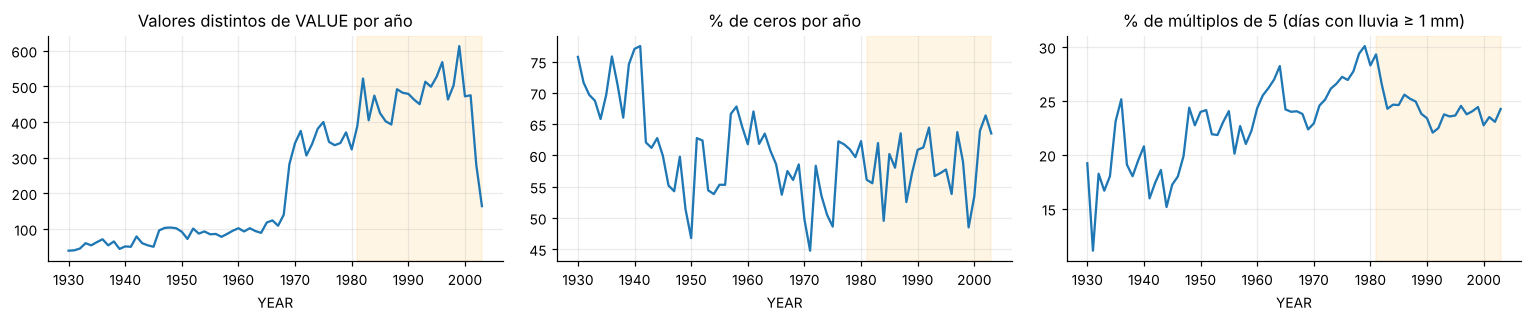

In [9]:
# Lo mismo por año: valores distintos, % de ceros, % con decimales y % de múltiplos de 5 entre los días con lluvia ≥ 1 mm
def m5(v):
    v = v[(v >= 1) & (v % 1 == 0)]; return 100 * (v % 5 == 0).mean()
anual = raw.groupby("YEAR").VALUE.agg(valores_distintos="nunique", ceros_pct=lambda v: 100 * (v == 0).mean(),
                                      decimales_pct=lambda v: 100 * (v % 1 != 0).mean(), multiplos5_pct=m5,
                                      maximo="max", mediana_lluvia=lambda v: v[v > 0].median()).round(2)
display(anual.T)
anual.to_csv(OUT / "valores_por_anio.csv")
fig, ax = plt.subplots(1, 3, figsize=(14, 3))
anual.valores_distintos.plot(ax=ax[0], title="Valores distintos de VALUE por año")
anual.ceros_pct.plot(ax=ax[1], title="% de ceros por año")
anual.multiplos5_pct.plot(ax=ax[2], title="% de múltiplos de 5 (días con lluvia ≥ 1 mm)")
for a in ax: a.axvspan(1981, 2003, color="orange", alpha=.1)
plt.tight_layout(); plt.show()


In [10]:
# Frecuencia de cada valor por año (tabla larga: año, valor, veces) y top de valores por estación
largo = raw.groupby(["YEAR", "VALUE"]).size().rename("veces").reset_index()
largo.to_csv(OUT / "frecuencia_valor_por_anio.csv", index=False)
top_est = (raw.groupby("STATION_ID").VALUE.agg(valores_distintos="nunique",
             valor_mas_frecuente_sin_cero=lambda v: v[v > 0].mode().iloc[0] if (v > 0).any() else np.nan,
             multiplos5_pct=m5).round(1).sort_values("multiplos5_pct", ascending=False))
display(top_est.head(10)); top_est.to_csv(OUT / "valores_por_estacion.csv")
print("Archivos guardados en eda_fase0/valores_unicos/:", sorted(p.name for p in OUT.iterdir()))


,valores_distintos,valor_mas_frecuente_sin_cero,multiplos5_pct
STATION_ID,,,
2621500102,80,10.0,71.5
2612200101,4,1.0,66.7
5301300101,141,20.0,65.2
5300600101,193,10.0,64.6
2612710104,80,10.0,62.5
2610300101,58,10.0,58.5
2610000113,107,10.0,58.2
5300900101,182,10.0,51.0
5300900103,87,10.0,49.0


Archivos guardados en eda_fase0/valores_unicos/: ['conteo_estacion_por_anio.csv', 'conteo_mes_por_anio.csv', 'conteo_por_anio.csv', 'conteo_por_estacion.csv', 'frecuencia_de_cada_valor.csv', 'frecuencia_valor_por_anio.csv', 'valores_por_anio.csv', 'valores_por_estacion.csv']


## 6. Qué nos dice este inventario

- **Calendario sin errores de formato:** 12 meses, 31 días y años 1930–2003, sin valores fuera de rango (el notebook 01 ya confirmó que no hay fechas imposibles ni duplicados).
- **Estaciones muy desiguales:** unas tienen décadas de registros y otras unos pocos años; cada estación aparece en uno, dos o los tres archivos. El conteo por estación y año (`conteo_estacion_por_anio.csv`) es la base del criterio de cobertura.
- **El día del mes no es neutro:** si el último día de algunos meses sale con más lluvia, es la huella de los totales mensuales digitados en un día (notebook 01, §4).
- **`VALUE` está casi todo en mm enteros** y tiene **preferencia de dígito**: los múltiplos de 5 (5, 10, 15, 20…) salen bastante más de lo que deberían según sus valores vecinos. Es un error de lectura u observación típico de pluviómetros manuales: el observador redondeaba a la marca más cercana. Para curvas anuales suavizadas su efecto es mínimo (el error es de ±2 mm en días puntuales y se promedia), pero conviene mencionarlo en el informe como una fuente de ruido de medición. Las estaciones con mayor % de múltiplos de 5 son las más redondeadas.
- **Casos para revisar que salen de este inventario:** la estación 5421200112 tiene media de 141 mm por registro y apenas 43 registros por año: son casi solo totales mensuales. La 2612200101 tiene exactamente 12 registros en 1985 (uno por mes). Y hay estaciones con más del 50 % de sus días lluviosos en múltiplos de 5 (2621500102, 5301300101, 5300600101, 2612710104…): sus series están muy redondeadas.
- **Más valores distintos con los años:** de ~50 valores distintos por año en los años 30 a ~500 en los 90. Se debe a más estaciones y a que aparecen decimales (0–3,6 % de los registros desde los 80), no a un cambio del clima.
- **Ceros:** la proporción de ceros por año da una idea del régimen y de posibles cambios de protocolo. Los ceros falsos ya se trataron en el notebook 01 (§6).